# TCN one-month-ahead TWS forecast: GRACE-only vs early vs late fusion

This notebook trains and evaluates the Temporal Convolutional Network (TCN) defined in
`scripts/tcn_forecast.py`; every setting is in `configs/tcn_config.yaml`.

**Task.** For each of the land cells in the shared aligned dataset, predict the TWS anomaly (cm) in month *t*
from a 12-month input window.

**Timing (nowcast, as in the P/T baselines).** To predict TWS(*t*) the window holds TWS(*t*−12 … *t*−1)
and precipitation/temperature anomalies P/T(*t*−11 … *t*).

**Models compared.**

| Model | Inputs | How fusion happens |
|---|---|---|
| TCN (GRACE only) | TWS history | – |
| TCN early fusion (GRACE + P,T) | TWS, P, T | stacked as input channels of one network |
| TCN (P,T only) | P, T | – (second late-fusion branch) |
| TCN late fusion (GRACE \| P,T) | the two branch forecasts | ŷ = a + w₁·ŷ_GRACE + w₂·ŷ_PT, fitted on 2023 |

**Protocol (same as the baselines).** Train on 2019–2022 targets, choose hyperparameters on 2023 by
area-weighted RMSE, refit the chosen configuration on 2019–2023 for its best epoch count, and score once on
the test months, on the same cells as the saved baseline predictions.

In [1]:
# Parameters (papermill can override these). QUICK_RUN trains a tiny grid for a fast end-to-end check.
QUICK_RUN = False

In [2]:
from pathlib import Path
import json
import sys
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import xarray as xr
from IPython.display import display


def find_project_root(start: Path) -> Path:
    for candidate in (start, *start.parents):
        if (candidate / "scripts" / "tcn_forecast.py").is_file():
            return candidate
    raise FileNotFoundError("Run the notebook from inside a clone of the repository.")


PROJECT_ROOT = find_project_root(Path.cwd().resolve())
sys.path.insert(0, str(PROJECT_ROOT / "scripts"))

import p_t_tws_data as alignment
import tcn_forecast as tcn
from grace_fo_processing import compressed_float_encoding
from p_t_tws_analysis import save_figure

%matplotlib inline
warnings.filterwarnings("ignore", category=RuntimeWarning)
print("PyTorch", torch.__version__, "| CUDA:", torch.cuda.is_available(), "| CPU threads:", torch.get_num_threads())

PyTorch 2.2.2 | CUDA: False | CPU threads: 8


## 1. Configuration

In [3]:
CONFIG_PATH = PROJECT_ROOT / "configs" / "tcn_config.yaml"
ALIGNED_FILE = PROJECT_ROOT / "data" / "processed" / "p_t_tws_aligned_0.5deg.nc"
BASELINE_PREDICTIONS = PROJECT_ROOT / "data" / "processed" / "p_t_tws_baseline_predictions.nc"
METRICS_DIR = PROJECT_ROOT / "results" / "metrics"
FIGURES_DIR = PROJECT_ROOT / "results" / "figures"
MODELS_DIR = PROJECT_ROOT / "models"
PREDICTIONS_FILE = PROJECT_ROOT / "data" / "processed" / "tcn_predictions.nc"
for directory in (METRICS_DIR, FIGURES_DIR, MODELS_DIR):
    directory.mkdir(parents=True, exist_ok=True)

config = tcn.load_tcn_config(CONFIG_PATH, project_root=PROJECT_ROOT)
if QUICK_RUN:  # smoke test only: one configuration, two short epochs
    config["grid"] = {"channels": [16], "dropout": [0.1], "learning_rate": [1e-3]}
    config["training"].update(max_epochs=2, samples_per_epoch=20_000)
torch.set_num_threads(config["training"]["threads"])

model_settings = config["model"]
print("Splits:", {name: (s["start"][:7], s["end"][:7]) for name, s in config["base"]["splits"].items()})
print("Timing:", config["data"]["timing"], "| lookback:", config["data"]["lookback_months"], "months",
      "| cell mask:", config["data"]["cell_mask"])
print("Runs:", config["runs"])
print("Late fusion:", config["late_fusion"])
print("Grid:", config["grid"], f"-> {len(tcn.grid(config))} configurations per run")
print("Training:", config["training"])

Splits: {'train': ('2019-01', '2022-12'), 'validation': ('2023-01', '2023-12'), 'test': ('2024-01', '2025-12')}
Timing: nowcast | lookback: 12 months | cell mask: training_mask
Runs: {'TCN (GRACE only)': ['tws'], 'TCN early fusion (GRACE + P,T)': ['tws', 'precip', 't2m'], 'TCN (P,T only)': ['precip', 't2m']}
Late fusion: {'name': 'TCN late fusion (GRACE | P,T)', 'branches': ['TCN (GRACE only)', 'TCN (P,T only)']}
Grid: {'channels': [16, 32, 64], 'dropout': [0.1, 0.3], 'learning_rate': [0.001, 0.0003]} -> 12 configurations per run
Training: {'max_epochs': 30, 'patience': 5, 'samples_per_epoch': 300000, 'seed': 42, 'threads': 8}


## 2. Shared aligned dataset

`p_t_tws_aligned_0.5deg.nc` is built by `scripts/p_t_tws_data.py`. Cells are selected with the
leakage-free `training_mask` (availability judged on the training period only).

In [4]:
with xr.open_dataset(ALIGNED_FILE) as aligned:
    cell_mask = config["data"]["cell_mask"]
    assert cell_mask in aligned, f"{ALIGNED_FILE.name} has no '{cell_mask}': rebuild it with p_t_tws_data.py"
    cube = alignment.PixelCube.from_dataset(aligned.assign(mask=aligned[cell_mask]))
rows = cube.split_rows(config["base"]["splits"])

observed = np.isfinite(cube.tws).any(1)
print(f"Grid cells used: {cube.n_pixels:,} | months: {cube.times[0]:%Y-%m} … {cube.times[-1]:%Y-%m} ({len(cube.times)})")
for name, selected in rows.items():
    months = cube.times[selected]
    print(f"  {name:10s} {months[0]:%Y-%m} … {months[-1]:%Y-%m}  ({selected.sum()} target months)")
gaps = cube.times[(cube.times >= "2017-01-01") & ~observed]
print("GRACE gap months since 2017 (zero-filled + flagged inside input windows):",
      ", ".join(f"{month:%Y-%m}" for month in gaps))

Grid cells used: 46,325 | months: 2000-06 … 2025-09 (304)
  train      2019-01 … 2022-12  (48 target months)
  validation 2023-01 … 2023-12  (12 target months)
  test       2024-01 … 2025-09  (21 target months)
GRACE gap months since 2017 (zero-filled + flagged inside input windows): 2017-02, 2017-07, 2017-08, 2017-09, 2017-10, 2017-11, 2017-12, 2018-01, 2018-02, 2018-03, 2018-04, 2018-05, 2018-08, 2018-09


## 3. Architecture

Four residual blocks of dilated **causal** 1-D convolutions (kernel 3, dilations 1-2-4-8). Each block is
CausalConv → ReLU → Dropout → CausalConv → ReLU → Dropout plus a skip connection. The last step's features go
through a linear head to give TWS(*t*). The loss is MSE weighted by cos(latitude), the same weighting used
in scoring.

In [5]:
example = tcn.TCN(n_inputs=6, channels=32, kernel_size=model_settings["kernel_size"],
                  dilations=model_settings["dilations"], dropout=0.1)
print(example)
print(f"Parameters (32 channels, 6 inputs): {sum(p.numel() for p in example.parameters()):,}")
print("Receptive field:", tcn.receptive_field(model_settings["kernel_size"], model_settings["dilations"]),
      "steps; lookback:", config["data"]["lookback_months"])

# Causality check: changing steps 6-11 must not change the block outputs at steps 0-5.
example.eval()
x = torch.randn(2, 12, 6)
changed = x.clone()
changed[:, 6:] += 10
with torch.no_grad():
    unchanged = torch.allclose(example.blocks(x.transpose(1, 2))[:, :, :6],
                               example.blocks(changed.transpose(1, 2))[:, :, :6])
print("Causal (past outputs unaffected by future inputs):", unchanged)

TCN(
  (blocks): Sequential(
    (0): TemporalBlock(
      (net): Sequential(
        (0): CausalConv1d(6, 32, kernel_size=(3,), stride=(1,))
        (1): ReLU()
        (2): Dropout(p=0.1, inplace=False)
        (3): CausalConv1d(32, 32, kernel_size=(3,), stride=(1,))
        (4): ReLU()
        (5): Dropout(p=0.1, inplace=False)
      )
      (skip): Conv1d(6, 32, kernel_size=(1,), stride=(1,))
    )
    (1): TemporalBlock(
      (net): Sequential(
        (0): CausalConv1d(32, 32, kernel_size=(3,), stride=(1,), dilation=(2,))
        (1): ReLU()
        (2): Dropout(p=0.1, inplace=False)
        (3): CausalConv1d(32, 32, kernel_size=(3,), stride=(1,), dilation=(2,))
        (4): ReLU()
        (5): Dropout(p=0.1, inplace=False)
      )
      (skip): Identity()
    )
    (2): TemporalBlock(
      (net): Sequential(
        (0): CausalConv1d(32, 32, kernel_size=(3,), stride=(1,), dilation=(4,))
        (1): ReLU()
        (2): Dropout(p=0.1, inplace=False)
        (3): CausalConv1d(32

## 4. Tests

In [6]:
import subprocess
result = subprocess.run([sys.executable, "-m", "unittest", "tests.test_tcn_forecast"], cwd=PROJECT_ROOT,
                        capture_output=True, text=True)
print(result.stderr.strip().splitlines()[-3:])
assert result.returncode == 0, result.stderr

['Ran 11 tests in 3.369s', '', 'OK']


## 5. Training

Each run trains the full hyperparameter grid on 2019–2022 with early stopping on 2023 validation RMSE,
then refits the best configuration on 2019–2023. Per-epoch output is printed below each cell.

In [7]:
experiments = {}


def train_run(label):
    started = time.time()
    experiments[label] = tcn.run_experiment(cube, config["runs"][label], config, label)
    table = pd.DataFrame([{k: v for k, v in r.items() if k not in ("history", "run")}
                          for r in experiments[label]["grid"]]).sort_values("val_rmse_cm")
    print(f"\n{label} finished in {(time.time() - started) / 60:.0f} min")
    display(table.round(3).reset_index(drop=True))

### TCN (GRACE only)

In [8]:
train_run("TCN (GRACE only)")

TCN (GRACE only): channels=['tws_prev', 'tws_prev_observed', 'month_sin', 'month_cos'], train samples=2,223,600, validation samples=555,900


  [1/12] {'channels': 16, 'dropout': 0.1, 'learning_rate': 0.001}


    epoch=1  train_rmse_cm=9.421  seconds=18.900  val_rmse_cm=4.432


    epoch=2  train_rmse_cm=5.156  seconds=20.300  val_rmse_cm=4.172


    epoch=3  train_rmse_cm=4.717  seconds=21.500  val_rmse_cm=4.002


    epoch=4  train_rmse_cm=4.478  seconds=24.100  val_rmse_cm=3.978


... (232 outputs left out)

    epoch=7  train_rmse_cm=3.985  seconds=40.200


    epoch=8  train_rmse_cm=3.928  seconds=40.900



TCN (GRACE only) finished in 460 min


,channels,dropout,learning_rate,best_epoch,val_rmse_cm,epochs_trained,seconds
0,32,0.1,0.001,8,3.857,13,597.3
1,32,0.1,0.000,13,3.871,18,862.8
2,64,0.3,0.001,22,3.873,27,1927.8
3,64,0.1,0.001,6,3.874,11,799.3
4,32,0.3,0.001,13,3.876,18,876.9
5,64,0.1,0.000,6,3.884,11,790.6
6,16,0.1,0.001,13,3.889,18,388.7
7,64,0.3,0.000,13,3.902,18,1169.6
8,32,0.3,0.000,13,3.905,18,886.8
9,16,0.3,0.001,13,3.921,18,349.5


### TCN early fusion (GRACE + P,T)

In [9]:
train_run("TCN early fusion (GRACE + P,T)")

TCN early fusion (GRACE + P,T): channels=['tws_prev', 'tws_prev_observed', 'precip_anom', 't2m_anom', 'month_sin', 'month_cos'], train samples=2,223,600, validation samples=555,900


  [1/12] {'channels': 16, 'dropout': 0.1, 'learning_rate': 0.001}


    epoch=1  train_rmse_cm=9.576  seconds=26.000  val_rmse_cm=4.647


    epoch=2  train_rmse_cm=5.090  seconds=25.300  val_rmse_cm=4.035


    epoch=3  train_rmse_cm=4.585  seconds=25.400  val_rmse_cm=3.903


    epoch=4  train_rmse_cm=4.346  seconds=25.000  val_rmse_cm=3.841


... (278 outputs left out)

    epoch=12  train_rmse_cm=3.638  seconds=67.500


    epoch=13  train_rmse_cm=3.610  seconds=65.700



TCN early fusion (GRACE + P,T) finished in 299 min


,channels,dropout,learning_rate,best_epoch,val_rmse_cm,epochs_trained,seconds
0,64,0.3,0.001,13,3.592,18,1144.7
1,64,0.1,0.000,8,3.620,13,802.6
2,32,0.1,0.000,29,3.620,30,1299.8
3,32,0.1,0.001,8,3.628,13,629.0
4,64,0.1,0.001,5,3.628,10,688.9
5,16,0.1,0.001,16,3.640,21,533.7
6,32,0.3,0.001,13,3.652,18,901.5
7,16,0.3,0.001,21,3.656,26,679.8
8,64,0.3,0.000,15,3.657,20,1389.2
9,16,0.1,0.000,26,3.675,30,752.8


### TCN (P,T only)

In [10]:
train_run("TCN (P,T only)")

TCN (P,T only): channels=['precip_anom', 't2m_anom', 'month_sin', 'month_cos'], train samples=2,223,600, validation samples=555,900


  [1/12] {'channels': 16, 'dropout': 0.1, 'learning_rate': 0.001}


    epoch=1  train_rmse_cm=19.793  seconds=27.300  val_rmse_cm=22.228


    epoch=2  train_rmse_cm=19.257  seconds=29.200  val_rmse_cm=21.944


    epoch=3  train_rmse_cm=19.073  seconds=29.300  val_rmse_cm=21.788


    epoch=4  train_rmse_cm=18.718  seconds=27.300  val_rmse_cm=21.784


... (191 outputs left out)

    epoch=16  train_rmse_cm=18.729  seconds=29.100


    epoch=17  train_rmse_cm=18.348  seconds=29.400



TCN (P,T only) finished in 156 min


,channels,dropout,learning_rate,best_epoch,val_rmse_cm,epochs_trained,seconds
0,16,0.1,0.001,17,21.496,22,610.5
1,16,0.3,0.001,14,21.629,19,470.6
2,32,0.3,0.001,4,21.681,9,441.7
3,16,0.3,0.000,22,21.718,27,768.4
4,16,0.1,0.000,14,21.737,19,545.4
5,32,0.3,0.000,14,21.759,19,840.2
6,64,0.3,0.000,4,21.774,9,593.1
7,64,0.1,0.000,4,21.842,9,620.7
8,64,0.1,0.001,1,21.843,6,398.9
9,32,0.1,0.001,3,21.846,8,367.2


## 6. Hyperparameter search summary

All grid results on the 2023 validation period, and the training curves of the selected configuration for
each run.

run                             TCN (GRACE only)  TCN (P,T only)  \
channels dropout learning_rate                                     
16       0.1     0.0003                    3.935          21.737   
                 0.0010                    3.889          21.496   
         0.3     0.0003                    3.958          21.718   
                 0.0010                    3.921          21.629   
32       0.1     0.0003                    3.871          21.862   
                 0.0010                    3.857          21.846   
         0.3     0.0003                    3.905          21.759   
                 0.0010                    3.876          21.681   
64       0.1     0.0003                    3.884          21.842   
                 0.0010                    3.874          21.843   
         0.3     0.0003                    3.902          21.774   
                 0.0010                    3.873          21.857   

run                             TCN early fusion (GRACE + P,T)  
channels dropout learning_rate                                  
16       0.1     0.0003                                  3.675  
                 0.0010                                  3.640  
         0.3     0.0003                                  3.732  
                 0.0010                                  3.656  
32       0.1     0.0003                                  3.620  
                 0.0010                                  3.628  
         0.3     0.0003                                  3.676  
                 0.0010                                  3.652  
64       0.1     0.0003                                  3.620  
                 0.0010                                  3.628  
         0.3     0.0003                                  3.657  
                 0.0010                                  3.592

,channels,dropout,learning_rate,refit_epochs,val_rmse_cm
TCN (GRACE only),32.0,0.1,0.001,8.0,3.857352
"TCN early fusion (GRACE + P,T)",64.0,0.3,0.001,13.0,3.591689
"TCN (P,T only)",16.0,0.1,0.001,17.0,21.495653


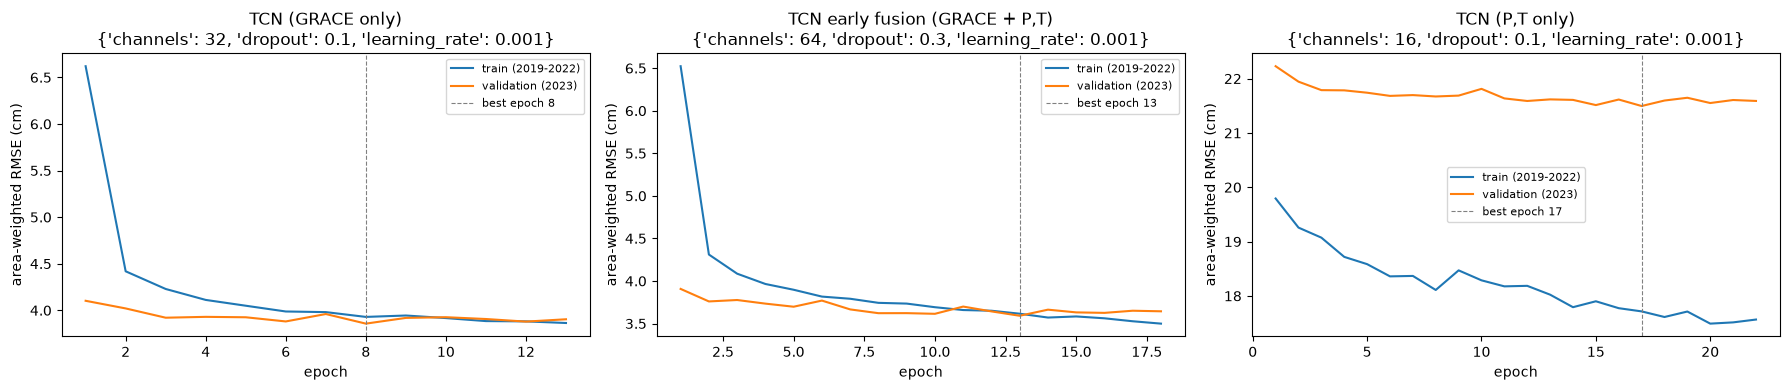

In [11]:
grid_table = pd.DataFrame([{k: v for k, v in r.items() if k != "history"}
                           for e in experiments.values() for r in e["grid"]])
display(grid_table.pivot_table(index=["channels", "dropout", "learning_rate"], columns="run",
                               values="val_rmse_cm").round(3))
selected = pd.DataFrame({label: {**e["params"], "refit_epochs": e["best_epoch"],
                                 "val_rmse_cm": min(r["val_rmse_cm"] for r in e["grid"])}
                         for label, e in experiments.items()}).T
display(selected)
fig = tcn.plot_learning_curves(list(experiments.values()))
plt.show()

## 7. Late fusion

The GRACE-only and P/T-only branches were trained separately. Their 2023 forecasts (from the models
trained on 2019–2022) fit the stacking weights by area-weighted least squares; the weights are then
applied to the refit branches. The test period is never used for fitting.

In [12]:
fusion = tcn.late_fusion(cube, list(experiments.values()), config)
display(pd.Series(fusion["coefficients"], name=fusion["label"]).round(3).to_frame())

Late fusion TCN late fusion (GRACE | P,T): intercept_cm=-0.016, weight[TCN (GRACE only)]=0.994, weight[TCN (P,T only)]=0.039, val_rmse_cm_in_sample=3.842


,"TCN late fusion (GRACE | P,T)"
intercept_cm,-0.016
weight[TCN (GRACE only)],0.994
"weight[TCN (P,T only)]",0.039
val_rmse_cm_in_sample,3.842


## 8. Test evaluation against the baselines

All models are scored on the same test cells: the baseline file's `test_eval_mask` (TWS observed at *t*
and *t*−1), intersected with cells where every model has a prediction. Metrics are area-weighted per-cell
means; MSESS is the pooled skill against climatology.

Test cells: 972,825 (months x pixels) in 21 months


,MAE_cm,RMSE_cm,r_area_wtd,anom_r_area_wtd,NSE_median,pct_NSE_pos,n_cells,MSESS_vs_clim
Seasonal persistence,2.347,2.958,0.797,0.618,0.655,88.715,46325.000,0.860
"TCN early fusion (GRACE + P,T)",2.388,3.009,0.787,0.634,0.673,85.716,46325.000,0.854
"TCN late fusion (GRACE | P,T)",2.435,3.062,0.800,0.635,0.657,90.098,46325.000,0.845
TCN (GRACE only),2.478,3.110,0.796,0.629,0.639,88.076,46325.000,0.842
"ARX (P,T,trend,TWS t-1)",2.896,3.482,0.816,0.667,0.592,81.764,46325.000,0.789
Persistence,3.482,4.249,0.742,0.575,0.546,95.883,46325.000,0.636
"LR (P,T) + trend",4.391,5.122,0.700,0.443,0.181,57.079,46325.000,0.514
"Seasonal-trend + GBM (P,T)",5.320,6.017,0.698,0.426,-0.093,47.309,46325.000,0.309
"LR (P,T)",5.500,6.255,0.666,0.385,-0.093,47.374,46325.000,0.141
Seasonal + trend,5.814,6.564,0.640,0.229,-0.189,43.499,46325.000,0.136


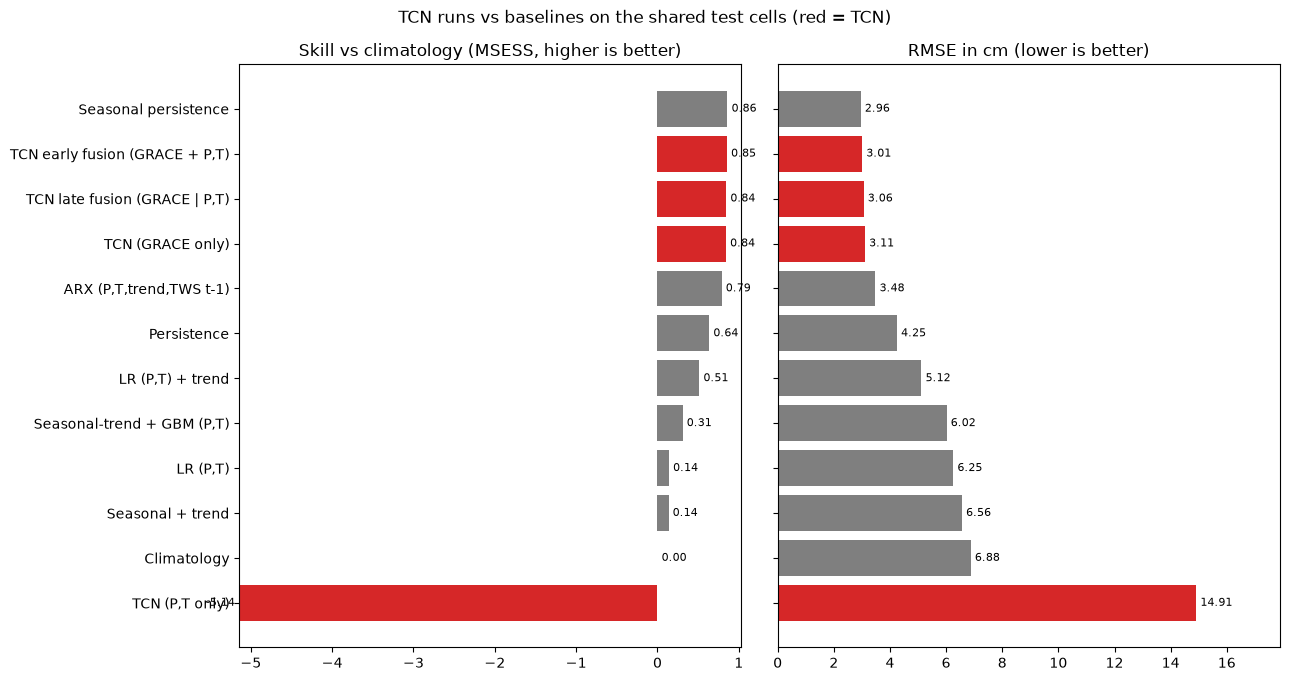

In [13]:
predictions = {label: e["prediction"] for label, e in experiments.items()}
predictions[fusion["label"]] = fusion["prediction"]
tcn_predictions = dict(predictions)

names_path = METRICS_DIR / "p_t_tws_baseline_metrics_gracefo.csv"
names = list(pd.read_csv(names_path, index_col=0).index) if names_path.is_file() else None
baseline_predictions, shared_mask = tcn.load_baseline_predictions(BASELINE_PREDICTIONS, cube, names)
predictions.update(baseline_predictions)

metrics, test_mask = tcn.score_models(cube, predictions, config, shared_mask)
display(metrics.style.format(precision=3).apply(
    lambda row: ["background-color: #fde2e1" if row.name in tcn_predictions else "" for _ in row], axis=1))
fig = tcn.plot_comparison(metrics, list(tcn_predictions))
plt.show()

### Fusion comparison

In [14]:
grace_only, early, late, drivers = list(config["runs"])[0], list(config["runs"])[1], fusion["label"], list(config["runs"])[2]
focus = metrics.loc[[grace_only, early, late, drivers, "Seasonal persistence"],
                    ["RMSE_cm", "MAE_cm", "anom_r_area_wtd", "MSESS_vs_clim"]]
focus["ΔRMSE vs GRACE-only (cm)"] = focus["RMSE_cm"] - metrics.loc[grace_only, "RMSE_cm"]
display(focus.round(3))
for label in (early, late):
    change = metrics.loc[label, "RMSE_cm"] - metrics.loc[grace_only, "RMSE_cm"]
    print(f"{label}: RMSE {'lower' if change < 0 else 'higher'} than GRACE-only by {abs(change):.3f} cm")
best = min((early, late), key=lambda label: metrics.loc[label, "RMSE_cm"])
gap = metrics.loc[best, "RMSE_cm"] - metrics.loc["Seasonal persistence", "RMSE_cm"]
print(f"Best fusion strategy: {best}; vs seasonal persistence: {gap:+.3f} cm RMSE")

,RMSE_cm,MAE_cm,anom_r_area_wtd,MSESS_vs_clim,ΔRMSE vs GRACE-only (cm)
TCN (GRACE only),3.110,2.478,0.629,0.842,0.000
"TCN early fusion (GRACE + P,T)",3.009,2.388,0.634,0.854,-0.101
"TCN late fusion (GRACE | P,T)",3.062,2.435,0.635,0.845,-0.048
"TCN (P,T only)",14.913,13.546,0.190,-5.144,11.803
Seasonal persistence,2.958,2.347,0.618,0.860,-0.152


TCN early fusion (GRACE + P,T): RMSE lower than GRACE-only by 0.101 cm
TCN late fusion (GRACE | P,T): RMSE lower than GRACE-only by 0.048 cm
Best fusion strategy: TCN early fusion (GRACE + P,T); vs seasonal persistence: +0.051 cm RMSE


### Where do precipitation and temperature help?

Per-cell test RMSE change relative to the GRACE-only TCN. Blue = the fusion model is more accurate there.

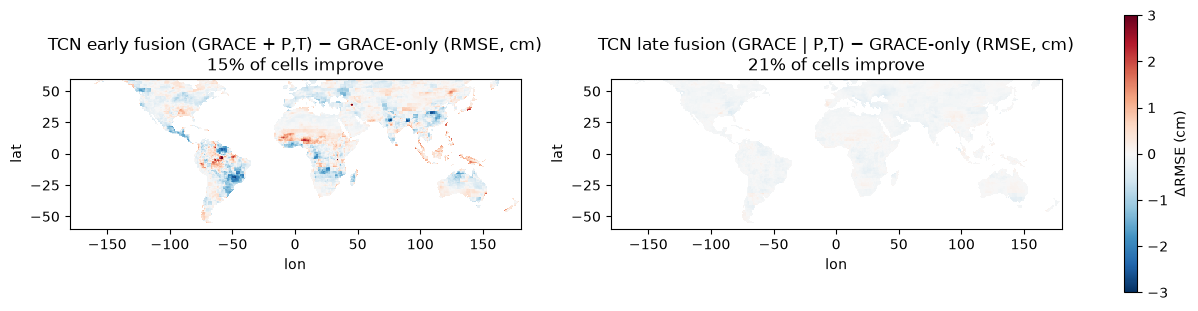

In [15]:
rows_all = cube.split_rows(config["base"]["splits"])
climatology = alignment.monthly_climatology(cube.tws, rows_all["train"] | rows_all["validation"], cube.month)
min_months = config["base"]["baselines"]["min_evaluation_months"]


def rmse_map(label):
    _, maps = tcn.evaluate_predictions(cube.tws, predictions[label], test_mask, cube.area_weight, cube.month,
                                       climatology, min_months=min_months)
    return maps["rmse"]


reference = rmse_map(grace_only)
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
for ax, label in zip(axes, (early, late)):
    difference = cube.to_map(rmse_map(label) - reference)
    image = ax.pcolormesh(difference.lon, difference.lat, difference, cmap="RdBu_r", vmin=-3, vmax=3, shading="auto")
    better = float(np.nanmean(difference.values < 0) * 100)
    ax.set(title=f"{label} − GRACE-only (RMSE, cm)\n{better:.0f}% of cells improve", xlabel="lon", ylabel="lat")
    ax.set_aspect("equal")
fig.colorbar(image, ax=axes, shrink=0.8, label="ΔRMSE (cm)")
plt.show()

## 9. Save outputs

In [16]:
if QUICK_RUN:
    print("QUICK_RUN: smoke test only, outputs not saved.")
else:
    grid_table.to_csv(METRICS_DIR / "tcn_grid_search.csv", index=False)
    metrics.to_csv(METRICS_DIR / "tcn_test_metrics.csv")
    for label, experiment in experiments.items():
        stem = "tcn_" + "_".join(experiment["sources"])
        torch.save(experiment["model"].state_dict(), MODELS_DIR / f"{stem}.pt")
        (MODELS_DIR / f"{stem}.json").write_text(
            json.dumps(tcn.specification(experiment, config, ALIGNED_FILE.relative_to(PROJECT_ROOT)), indent=2, default=str) + "\n")
    (MODELS_DIR / "tcn_late_fusion.json").write_text(json.dumps(
        {"model": fusion["label"], "branches": fusion["branches"], "combiner": "area-weighted linear stacking",
         "fit_on": "validation predictions of the train-only branch models", **fusion["coefficients"]}, indent=2) + "\n")
    dataset = tcn.prediction_dataset(cube, tcn_predictions, test_mask, config["data"]["timing"])
    dataset.to_netcdf(PREDICTIONS_FILE, engine="netcdf4", encoding=compressed_float_encoding(dataset))
    save_figure(tcn.plot_comparison(metrics, list(tcn_predictions)), FIGURES_DIR / "tcn_01_comparison.png")
    save_figure(tcn.plot_learning_curves(list(experiments.values())), FIGURES_DIR / "tcn_02_learning_curves.png")
    plt.close("all")
    print("Saved metrics, models, predictions and figures.")

Saved metrics, models, predictions and figures.
